# Dataset Type

In [1]:
DATASET_TYPE = "downloaded" # Options are "internal" or "downloaded"

# Load Scikit-Learn Internal Data

In [ ]:
# Import scikit-learn dataset library
from sklearn import datasets

if DATASET_TYPE == "internal":
  lr_data = datasets.load_iris()

  X = lr_data.data
  y = lr_data.target
  feature_names = lr_data.feature_names
  labels = lr_data.target_names
  cm_labels = labels

# OR: Download Real Dataset

In [2]:
import numpy as np
import pandas as pd

if DATASET_TYPE == "downloaded":
  lr_data = pd.read_csv('https://docs.google.com/spreadsheets/d/1v0SoHvdro_Jm_3eNMBEO16X6wNDFigi9EGycsECS_Lo/pub?output=csv')

  X = lr_data.iloc[:, 2:]
  y = lr_data.iloc[:, 1]
  feature_names = lr_data.columns
  labels = feature_names[1]
  cm_labels = ["malignant", "benign"]

  # Map labels from ['M', 'B'] to [0, 1] space
  y = np.where(y=='M', 0, 1)

# Explore the Data

In [3]:
# print the names of the features
print("Features: ", feature_names)

# print the label type of targets
print("Labels: ", labels)

Features:  Index(['I1', 'O', 'I2', 'I3', 'I4', 'I5', 'I6', 'I7', 'I8', 'I9', 'I10', 'I11',
       'I12', 'I13', 'I14', 'I15', 'I16', 'I17', 'I18', 'I19', 'I20', 'I21',
       'I22', 'I23', 'I24', 'I25', 'I26', 'I26.1', 'I28', 'I29', 'I30', 'I31'],
      dtype='object')
Labels:  O


# Scale the data

In [5]:
# Image processing and pixel values - min-max scaling
# knn-clustering or regression which use distance metrics - standardization
# SVM or logistic regression or Neural Network which use gradiant descent - standardization
# decision tree and random forest - not distance based, hence no scaling is needed

# Normalize the data - Convert to range [0, 1]
X = (X - np.min(X)) / (np.max(X) - np.min(X))

# Standardize the data - Convert to a normal distribution with mean 0 and standard deviation of 1
# X = (X - np.mean(X)) / np.std(X)


When we normalize the data we are scaling it to be in the range of [0, 1]. This means we take;

X = original data
Xmin = the minimum value in each column
Xmax = the maximum value in each column

and we format the minimum to be 0, and divide it by the shifted range to create a maximum value of 1. This scales the data to be the percentile in a range of min to max, with those respective values representing 0% to 100% of the maximum value in a column.

# Split the Data into Train and Test Sets

In [6]:
# Import train_test_split function
from sklearn.model_selection import train_test_split

# Here we split the training data set, and set it to 70% of the original data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.7)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((170, 30), (399, 30), (170,), (399,))

# Train the Model

In [33]:
from sklearn.linear_model import LogisticRegression
import time

# Update hyperparameters for the LogisticRegression function using paraemters defined in -
# https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

# Create Logistic Regression object
clf = LogisticRegression()

# Calculate time before training occurs
time_before = time.time()

# Train Logistic Regression Classifer
clf.fit(X_train, y_train)

# Calculate time after training occurs and display total time to train
time_after = time.time()
time_elapsed = time_after - time_before
time_elapsed = format(time_elapsed, ".4e")
print("Execution Time:", time_elapsed)

Execution Time: 1.9987e-03


Above is where the Model is Initialized and trained.

# Predict the Model on Test Data

In [23]:
#Predict the response for test dataset
y_pred = clf.predict(X_test)

# Evaluate on Test data

In [24]:
#Import scikit-learn metrics module for accuracy calculation
from sklearn import metrics

# Model Accuracy: how often is the classifier correct?
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))

# Model Precision: what percentage of positive tuples are labeled as such?
#print("Precision:",metrics.precision_score(y_test, y_pred))

# Model Recall: what percentage of positive tuples are labelled as such?
#print("Recall:",metrics.recall_score(y_test, y_pred))

Accuracy: 0.8320802005012531


# Plot Confusion Matrix

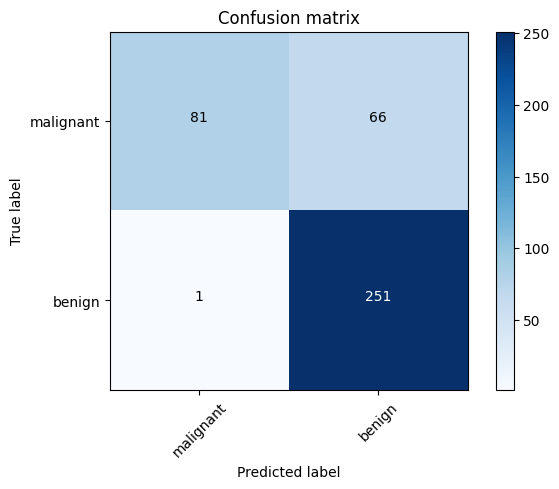

In [25]:
import itertools
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

def plot_confusion_matrix(cm, classes, normalize=False, title='Confusion matrix', cmap=plt.cm.Blues):
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    fmt = '.2f' if normalize else 'd'
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt), horizontalalignment="center", color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

cm = confusion_matrix(y_test, y_pred)

plot_confusion_matrix(cm, cm_labels)  
plt.show()

# Printing Performance Statistics for Part 4

In [39]:
# Assuming you have the confusion matrix and labels
# cm = confusion_matrix(y_test, y_pred)

# Extract TP, TN, FP, and FN from the confusion matrix (assuming a binary classification)
TP = cm[0, 0]  # True positives (predicted malignant and actually malignant)
FN = cm[0, 1]  # False negatives (predicted benign but actually malignant)
FP = cm[1, 0]  # False positives (predicted malignant but actually benign)
TN = cm[1, 1]  # True negatives (predicted benign and actually benign)

# Calculate the metrics
accuracy = (TP + TN) / (TP + TN + FP + FN)
misclassification = (FP + FN) / (TP + TN + FP + FN)
precision = TP / (TP + FP)
recall = TP / (TP + FN)  # Sensitivity
specificity = TN / (TN + FP)

# Print the calculated metrics with tabs for alignment
print(f"Accuracy:\t\t {accuracy:.4f}")
print(f"Misclassification:\t {misclassification:.4f}")
print(f"Precision:\t\t {precision:.4f}")
print(f"Recall (Sensitivity):\t {recall:.4f}")
print(f"Specificity:\t\t {specificity:.4f}")
print("Execution Time:\t\t", time_elapsed)


Accuracy:		 0.8321
Misclassification:	 0.1679
Precision:		 0.9878
Recall (Sensitivity):	 0.5510
Specificity:		 0.9960
Execution Time:		 1.9987e-03
